In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
root = Path.cwd()

if root.name == "notebooks":
    root = root.parent

df = pd.read_csv(root / "data/processed/ai4i_cleaned.csv")

df.head()

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


In [5]:
df_engineered = df.copy()

In [6]:
df_engineered["Temperature difference"] = (
    df_engineered["Process temperature"] -
    df_engineered["Air temperature"]
)

In [7]:
df_engineered["Mechanical power"] = (
    df_engineered["Torque"] *
    df_engineered["Rotational speed"] *
    2 * np.pi / 60
)

In [8]:
df_engineered["Wear load"] = (
    df_engineered["Tool wear"] *
    df_engineered["Torque"]
)

In [12]:
df_engineered.head()

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,Temperature difference,Mechanical power,Wear load
0,M,298.1,308.6,1551,42.8,0,0,10.5,6951.590560,0.0
1,L,298.2,308.7,1408,46.3,3,0,10.5,6826.722724,138.9
2,L,298.1,308.5,1498,49.4,5,0,10.4,7749.387543,247.0
3,L,298.2,308.6,1433,39.5,7,0,10.4,5927.504659,276.5
4,L,298.2,308.7,1408,40.0,9,0,10.5,5897.816608,360.0


In [13]:
df_engineered.shape

(10000, 10)

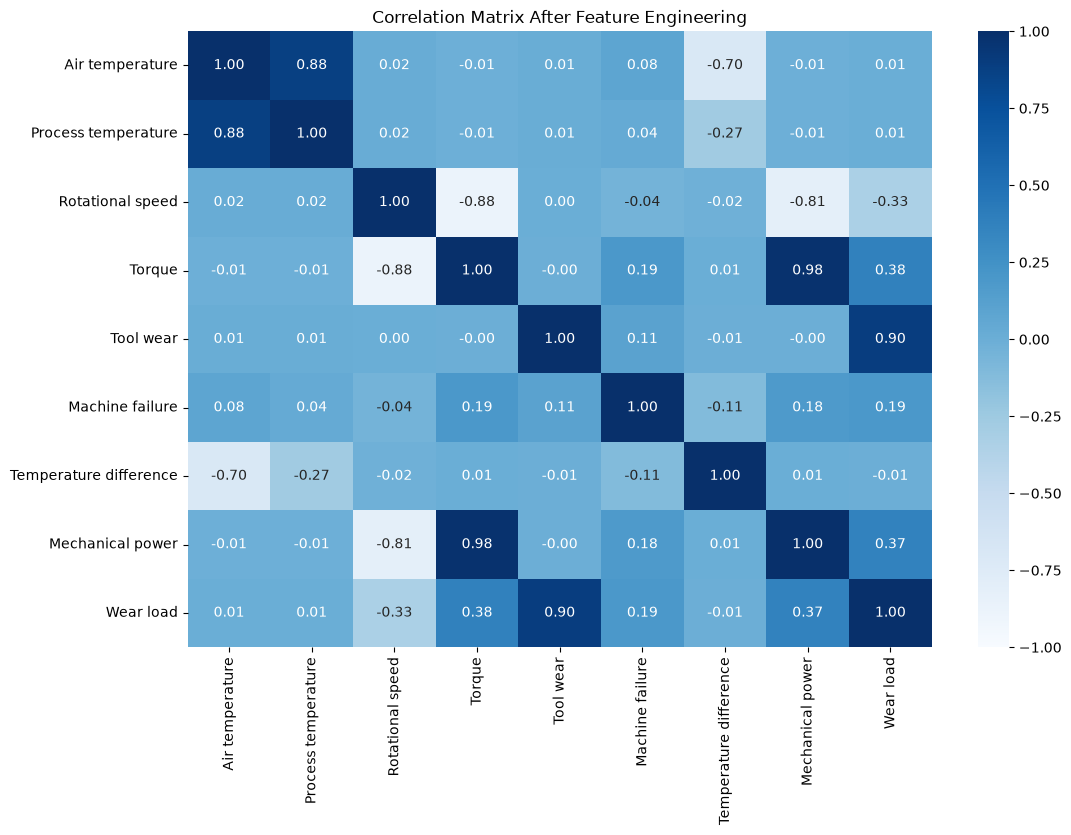

In [15]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_engineered.corr(numeric_only=True),
    annot=True,
    cmap="Blues",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix After Feature Engineering")
plt.show()

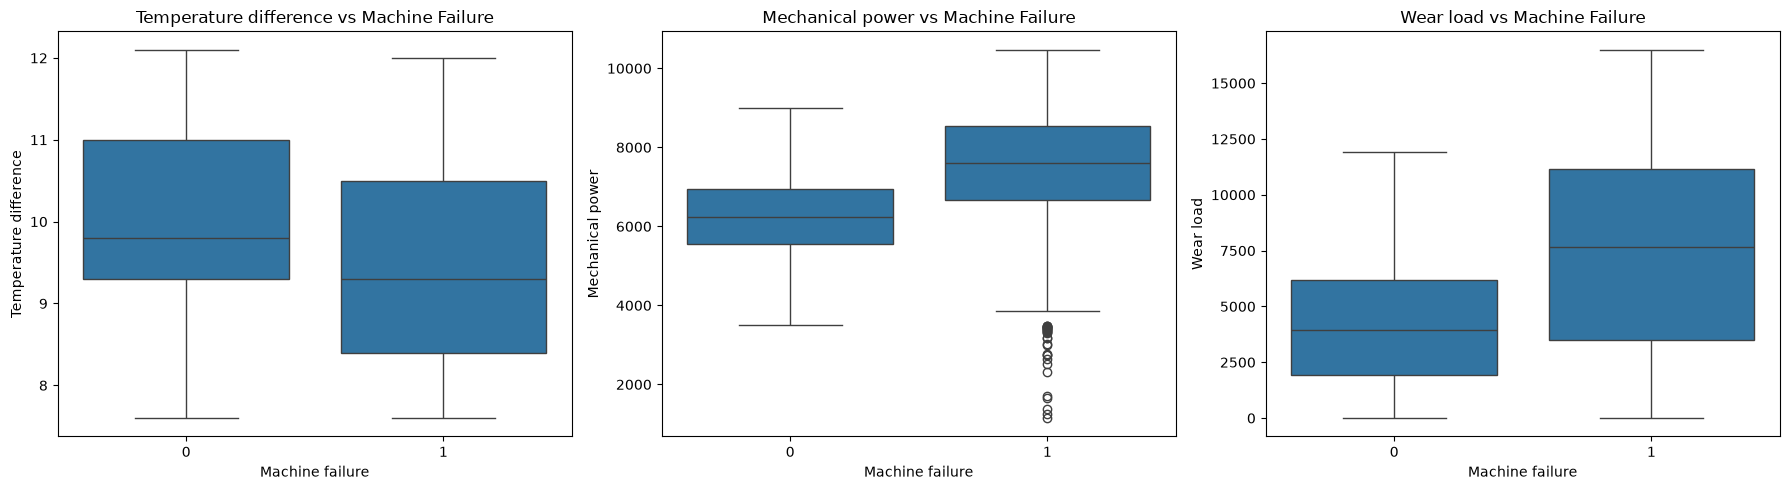

In [16]:
features = [
    "Temperature difference",
    "Mechanical power",
    "Wear load"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(features):

    sns.boxplot(
        data=df_engineered,
        x="Machine failure",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs Machine Failure")

plt.tight_layout()
plt.show()

In [17]:
df_engineered.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Type                    10000 non-null  str    
 1   Air temperature         10000 non-null  float64
 2   Process temperature     10000 non-null  float64
 3   Rotational speed        10000 non-null  int64  
 4   Torque                  10000 non-null  float64
 5   Tool wear               10000 non-null  int64  
 6   Machine failure         10000 non-null  int64  
 7   Temperature difference  10000 non-null  float64
 8   Mechanical power        10000 non-null  float64
 9   Wear load               10000 non-null  float64
dtypes: float64(6), int64(3), str(1)
memory usage: 781.4 KB


In [18]:
df_engineered.describe()

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,Temperature difference,Mechanical power,Wear load
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,10.000630,6279.744953,4314.664550
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,1.001094,1067.418295,2826.567692
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,7.600000,1148.440610,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,9.300000,5561.184484,1963.650000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,9.800000,6271.027344,4012.950000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,11.000000,7003.002724,6279.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,12.100000,10469.923005,16497.000000


In [20]:
df_engineered.to_csv(
    root / "data/processed/ai4i_engineered.csv",
    index=False
)

### Feature Engineering Findings

- Temperature difference is generally lower in failure observations.
- Mechanical power exhibits a potentially nonlinear relationship
  with machine failure.
- Both extremely low and high mechanical power values are
  associated with failure observations.
- Wear load has a substantially higher median in failure
  observations.
- Original and engineered features are retained for model comparison.
- Predictive usefulness will be evaluated through model validation.